# Acoplador de rejilla estándar: optimización de parámetros

## Configuración

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

# SOI grating-coupler dimensions [um]
w_wg = 0.5
taper_length = 15.0
n_periods = 16
fill_factor = 0.471
fiber_angle = 7.978  # in clad
taper_angle = 40.0
period = 0.6324
x_offset = -0.815  # fiber shift along x from grating port

# SOI dimensions [um]: 220 nm silicon with a 120 nm residual slab
h_core = 0.22
h_teeth = .08
h_slab = h_core - h_teeth
# h_box = 2.0  # buried oxide
# h_sub = 0.3  # substrate thickness in domain, continues into PML

# wavelengths [um]
wavelength = 1.55
bandwidth = 0.1
nwls = 11
wavelengths = np.linspace(wavelength - bandwidth / 2, wavelength + bandwidth / 2, nwls)

# Gaussian fiber mode dimensions [um]
D_beam = 10.4  # mode field diameter, SMF-28
Dlim = 1.5 * D_beam  # beam frame width


def setup(path, wavelength, wavelengths,n_periods, period,fill_factor, taper_length, taper_angle, x_offset=0, fiber_angle=fiber_angle):
    boundaries = ["PML", ["PEC", "PML"], "PML"]
    nres = 10
    shutoff = 1e-4
    tmax = 1000  # max time [periods]
    PML_decay = [0.001, 0.01, 0.001]
    shot_every = 10

    l_wg = 2

    source_offset = .3
    margin = zmargin = 1.2
    zmin =  - zmargin
    # zmin = -h_box - h_sub
    fiber_offset=zmargin+source_offset
    zmax = h_core + fiber_offset
    z_port = zmax - source_offset

    nclad = 1.444
    materials = {
        "Si": lumi.material(3.478),
        "SiO2": lumi.material(nclad),
    }
    background = "SiO2"

    WG = (1, 0)
    SLAB = (2, 0)
    BBOX = (3, 0)
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_core,
                zmin=0,
                material="Si",
                mesh_order=200,
            ),
            # "substrate": LayerLevel(
            #     layer=LogicalLayer(layer=BBOX),
            #     thickness=h_sub,
            #     zmin=zmin,
            #     material="Si",
            #     mesh_order=300,
            # ),
            "slab": LayerLevel(
                layer=LogicalLayer(layer=SLAB),
                thickness=h_slab,
                zmin=0,
                material="Si",
                mesh_order=100,
            ),
        }
    )

    c = gf.Component()
    gc = c << gf.components.grating_coupler_elliptical_uniform(
        n_periods=n_periods,
        period=period,
        fill_factor=fill_factor,
        taper_length=taper_length,
        taper_angle=taper_angle,
        wavelength=wavelength,
        fiber_angle=fiber_angle,
        nclad=nclad,
        layer_slab=SLAB,
        cross_section=gf.cross_section.cross_section(width=w_wg, layer=WG),
    )
    wg = c << gf.components.straight(
        length=l_wg,
        cross_section=gf.cross_section.cross_section(width=w_wg, layer=WG),
    )
    wg.connect("o2", gc.ports["o1"])
    # c << gf.components.bbox(component=c, layer=BBOX, top=margin, bottom=margin)
    x_fiber = gc.ports["o2"].x + x_offset + np.sin(np.deg2rad(fiber_angle)) * fiber_offset
    c << gf.components.bbox(  # enclose fiber frame
        component=c,
        layer=BBOX,
        top=margin,
        bottom=margin,
        right=max(0, x_fiber + Dlim / 2 - gc.xmax),
    )
    full_bbox = c.bbox_np().tolist()

    clipper = gf.Component()
    clipper_ref = clipper << gf.components.rectangle(
        size=(full_bbox[1][0] - full_bbox[0][0], full_bbox[1][1]),
        layer=WG,
    )

    half_component = gf.Component()
    clipper_ref.movex(full_bbox[0][0])
    for layer in (WG, SLAB, BBOX):
        clipped = gf.boolean(
            c,
            clipper,
            operation="and",
            layer=layer,
            layer1=layer,
            layer2=WG,
        )
        half_component << clipped
    half_component.add_port("wg", port=wg.ports["o1"])
    half_component.flatten()
    c = half_component
    c.plot()

    bbox = c.bbox_np().tolist()
    bbox[0][1] = 0
    bbox[0].append(zmin)
    bbox[1].append(zmax)

# sources, monitors
    frames = [
        lumi.plane_frame(
            "wg",
            start=[-w_wg / 2 - margin, -zmargin],
            stop=[0, h_core + zmargin],
            boundaries=[("PML", "PEC"), "PML"],
            wls_mode_solver=[wavelength],
        ),
        lumi.plane_frame(
            "fiber",
            modes=[
                [
                    lumi.gaussian_mode(
                        D_beam,
                        nclad,
                        dx=wavelength / nclad / nres,
                        theta=np.deg2rad(fiber_angle),
                        wl=wavelength,
                        half="y+",
                        Dlim=Dlim,
                    )
                ]
            ],
            start=[-Dlim / 2, 0],
            stop=[Dlim / 2, Dlim / 2],
        ),
    ]

    fiber_origin = [
        gc.ports["o2"].center[0] + x_offset + np.sin(np.deg2rad(fiber_angle)) * fiber_offset,
        0,
        zmax,  # source above fiber monitor, on fiber axis
    ]
    monitor_origin = [  # fiber monitor below source
        gc.ports["o2"].center[0] + x_offset + np.sin(np.deg2rad(fiber_angle)) * zmargin,
        0,
        z_port,
    ]
    fiber_basis = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
    sources = [
        lumi.source(
            "fiber",
            fiber_origin,
            fiber_basis,
            frame="fiber",
            wl=wavelength,
            bandwidth= wavelength / 8,
        )
    ]
    monitors = [
        lumi.gf_monitor("wg", c, layer_stack, frame="wg"),
        lumi.monitor("fiber", monitor_origin, fiber_basis, frame="fiber"),
    ]

    views = [lumi.view("Ey", y=0, z=h_slab+h_teeth / 2)]
    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background=background,
        boundaries=boundaries,
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=tmax,
        shutoff=shutoff,
        PML_decay=PML_decay,
        views=views,
        shot_every=shot_every,
    )


## Optimización

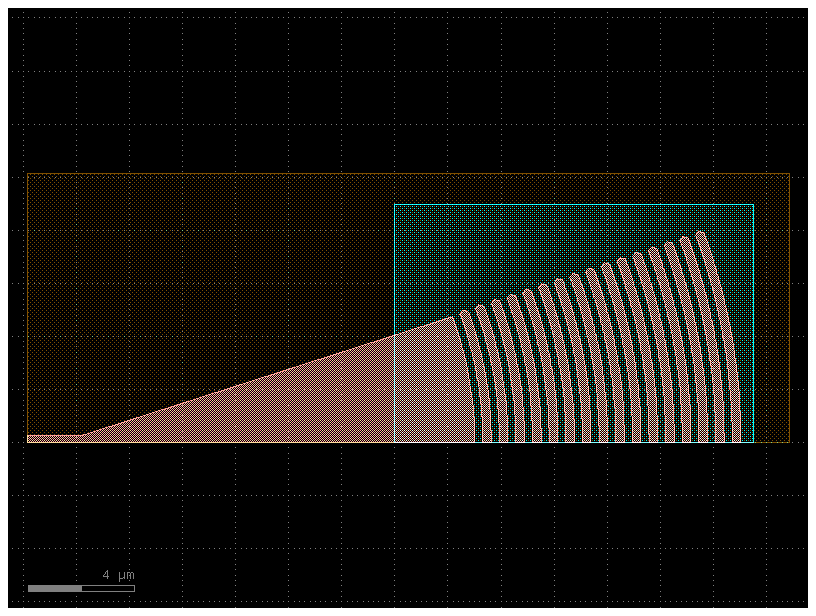

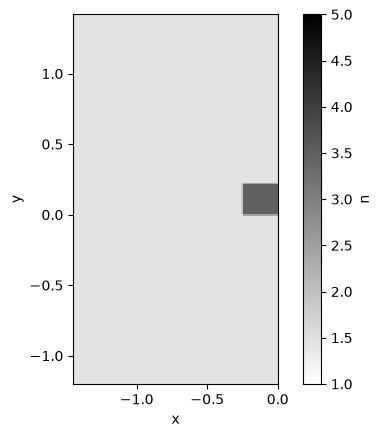

using simulation folder runs/GC_best
backend using simulation folder runs/GC_best
setting up simulation...
max cell grade per axis: Float32[1.454, 1.201, 1.2]
processing geometry bodies...
generating voxels...
voxelation: 3.131194 seconds (53.46 M allocations: 1.482 GiB, 7.25% gc time, 221.87% compilation time)
Yee mode λ=1.0: neff 2.4523
making sources fiber ...
making monitors fiber wg ...
run: runs/GC_best
processor: GPU
cpu threads: 48

nres: 10.0
courant: 0.9
subpixel_smoothing: 1
  
boundaries: [:PML :PML; :PEC :PML; :PML :PML]

sources
   fiber: 19.07, 0, 1.72 

monitors
   fiber: 19.03, 0, 1.42 
   wg: -1.84, 0, 0 

original size: (665, 232, 43)
padded size: (726, 247, 79)
cell count: 14,166,438

step size: 69.0 steps/period
source duration: 7.97 periods

max time: 1,000 periods
max steps: 69,000
max load: 977,484,222,000 cell-steps
energy decay threshold: 0.001

running simulation...
accumulating dft field...
period 10, decay: 0.53, 0.93 seconds/period, 1046.28 Mcells/s
period

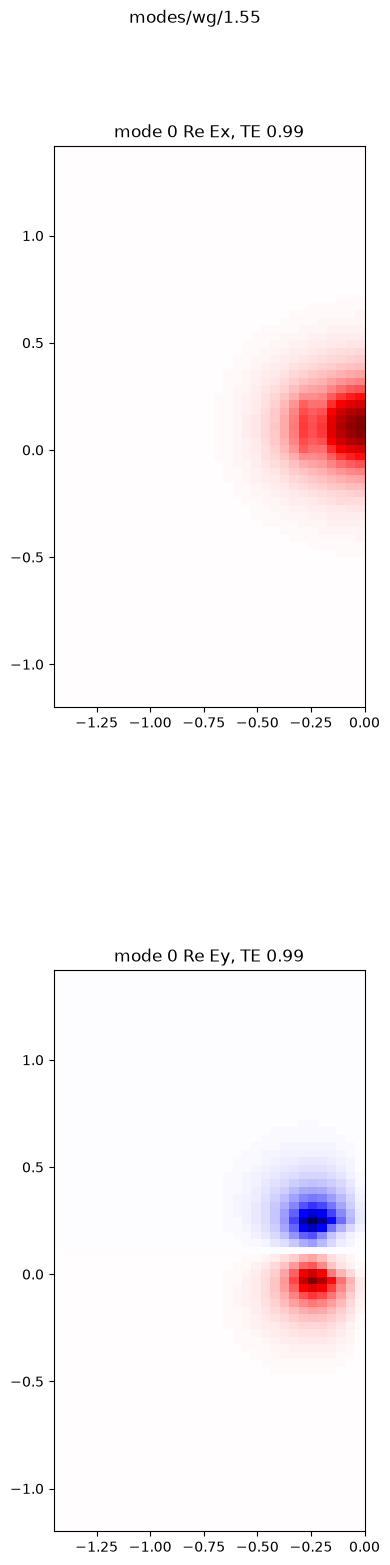

In [2]:
# best of a 15-simulation Nelder-Mead run over fiber_angle, period, fill_factor, x_offset (commented out below)
fiber_angle, period, fill_factor, x_offset = 8.412, 0.6268, 0.510, -1.081
path = os.path.join("runs", "GC_best")
setup(path, wavelength, wavelengths, n_periods, period, fill_factor, taper_length, taper_angle, x_offset=x_offset, fiber_angle=fiber_angle)
lumi.solve(path)

# from scipy.optimize import minimize

# # Nelder-Mead over fiber_angle, period, fill_factor, x_offset. n_periods, taper fixed
# # a uniform grating coupler reaches ~0.4 efficiency at best. for better, use apodization or inverse design
# maxsims = 15
# x0 = [fiber_angle, period, fill_factor, x_offset]
# steps = [1.0, 0.01, 0.03, 0.5]  # initial simplex steps
# x_history = []
# efficiency_history = []
# power_history = []  # incident power at fiber monitor


# class Done(Exception):
#     pass


# def loss(x):
#     i = len(x_history)
#     if i >= maxsims:
#         raise Done
#     fiber_angle, period, fill_factor, x_offset = x
#     path = os.path.join("runs", f"GC_opt_{i}")
#     setup(path, wavelength, wavelengths, n_periods, period, fill_factor, taper_length, taper_angle, x_offset=x_offset, fiber_angle=fiber_angle)
#     lumi.solve(path)
#     plt.close("all")

#     sol = lumi.load(path)
#     fiber_mode = sol["monitors"]["fiber"]["modes"][0]["-"][nwls // 2]
#     wg_mode = sol["monitors"]["wg"]["modes"][0]["+"][nwls // 2]
#     power = np.abs(fiber_mode) ** 2
#     efficiency = np.abs(wg_mode / fiber_mode) ** 2

#     x_history.append(list(x))
#     efficiency_history.append(efficiency)
#     power_history.append(power)
#     print(f"{i}: fiber_angle={fiber_angle:.3f}, period={period:.4f}, fill_factor={fill_factor:.3f}, x_offset={x_offset:.3f}, incident power={power:.4g}, efficiency={efficiency:.4f}")
#     # incident power should not depend on fiber angle
#     assert abs(power / power_history[0] - 1) < 0.05, "incident power changed"
#     return -efficiency


# simplex = [x0] + [[v + d * (j == k) for k, v in enumerate(x0)] for j, d in enumerate(steps)]
# try:
#     minimize(loss, x0, method="Nelder-Mead", options={"initial_simplex": simplex})
# except Done:
#     pass

# best = int(np.argmax(efficiency_history))
# fiber_angle, period, fill_factor, x_offset = x_history[best]
# path = os.path.join("runs", f"GC_opt_{best}")
# print(f"best: iteration {best}, efficiency={efficiency_history[best]:.4f}")


## Resultados

loading solution from runs/GC_best
may take a minute if simulation folder is remotely mounted
fiber_angle=8.412, period=0.6268, fill_factor=0.510, x_offset=-1.081, efficiency=0.3468 at 1.55 um


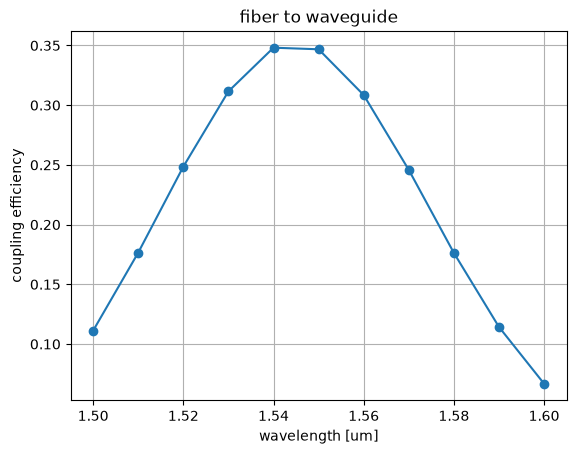

In [3]:
sol = lumi.load(path)
fiber_mode = np.array(sol["monitors"]["fiber"]["modes"][0]["-"])
wg_mode = np.array(sol["monitors"]["wg"]["modes"][0]["+"])
S = np.abs(wg_mode / fiber_mode) ** 2
print(f"fiber_angle={fiber_angle:.3f}, period={period:.4f}, fill_factor={fill_factor:.3f}, x_offset={x_offset:.3f}, efficiency={S[nwls // 2]:.4f} at {wavelength} um")

plt.plot(wavelengths, S, "o-")
plt.xlabel("wavelength [um]")
plt.ylabel("coupling efficiency")
plt.title("fiber to waveguide")
plt.grid(True)
plt.show()

## Película

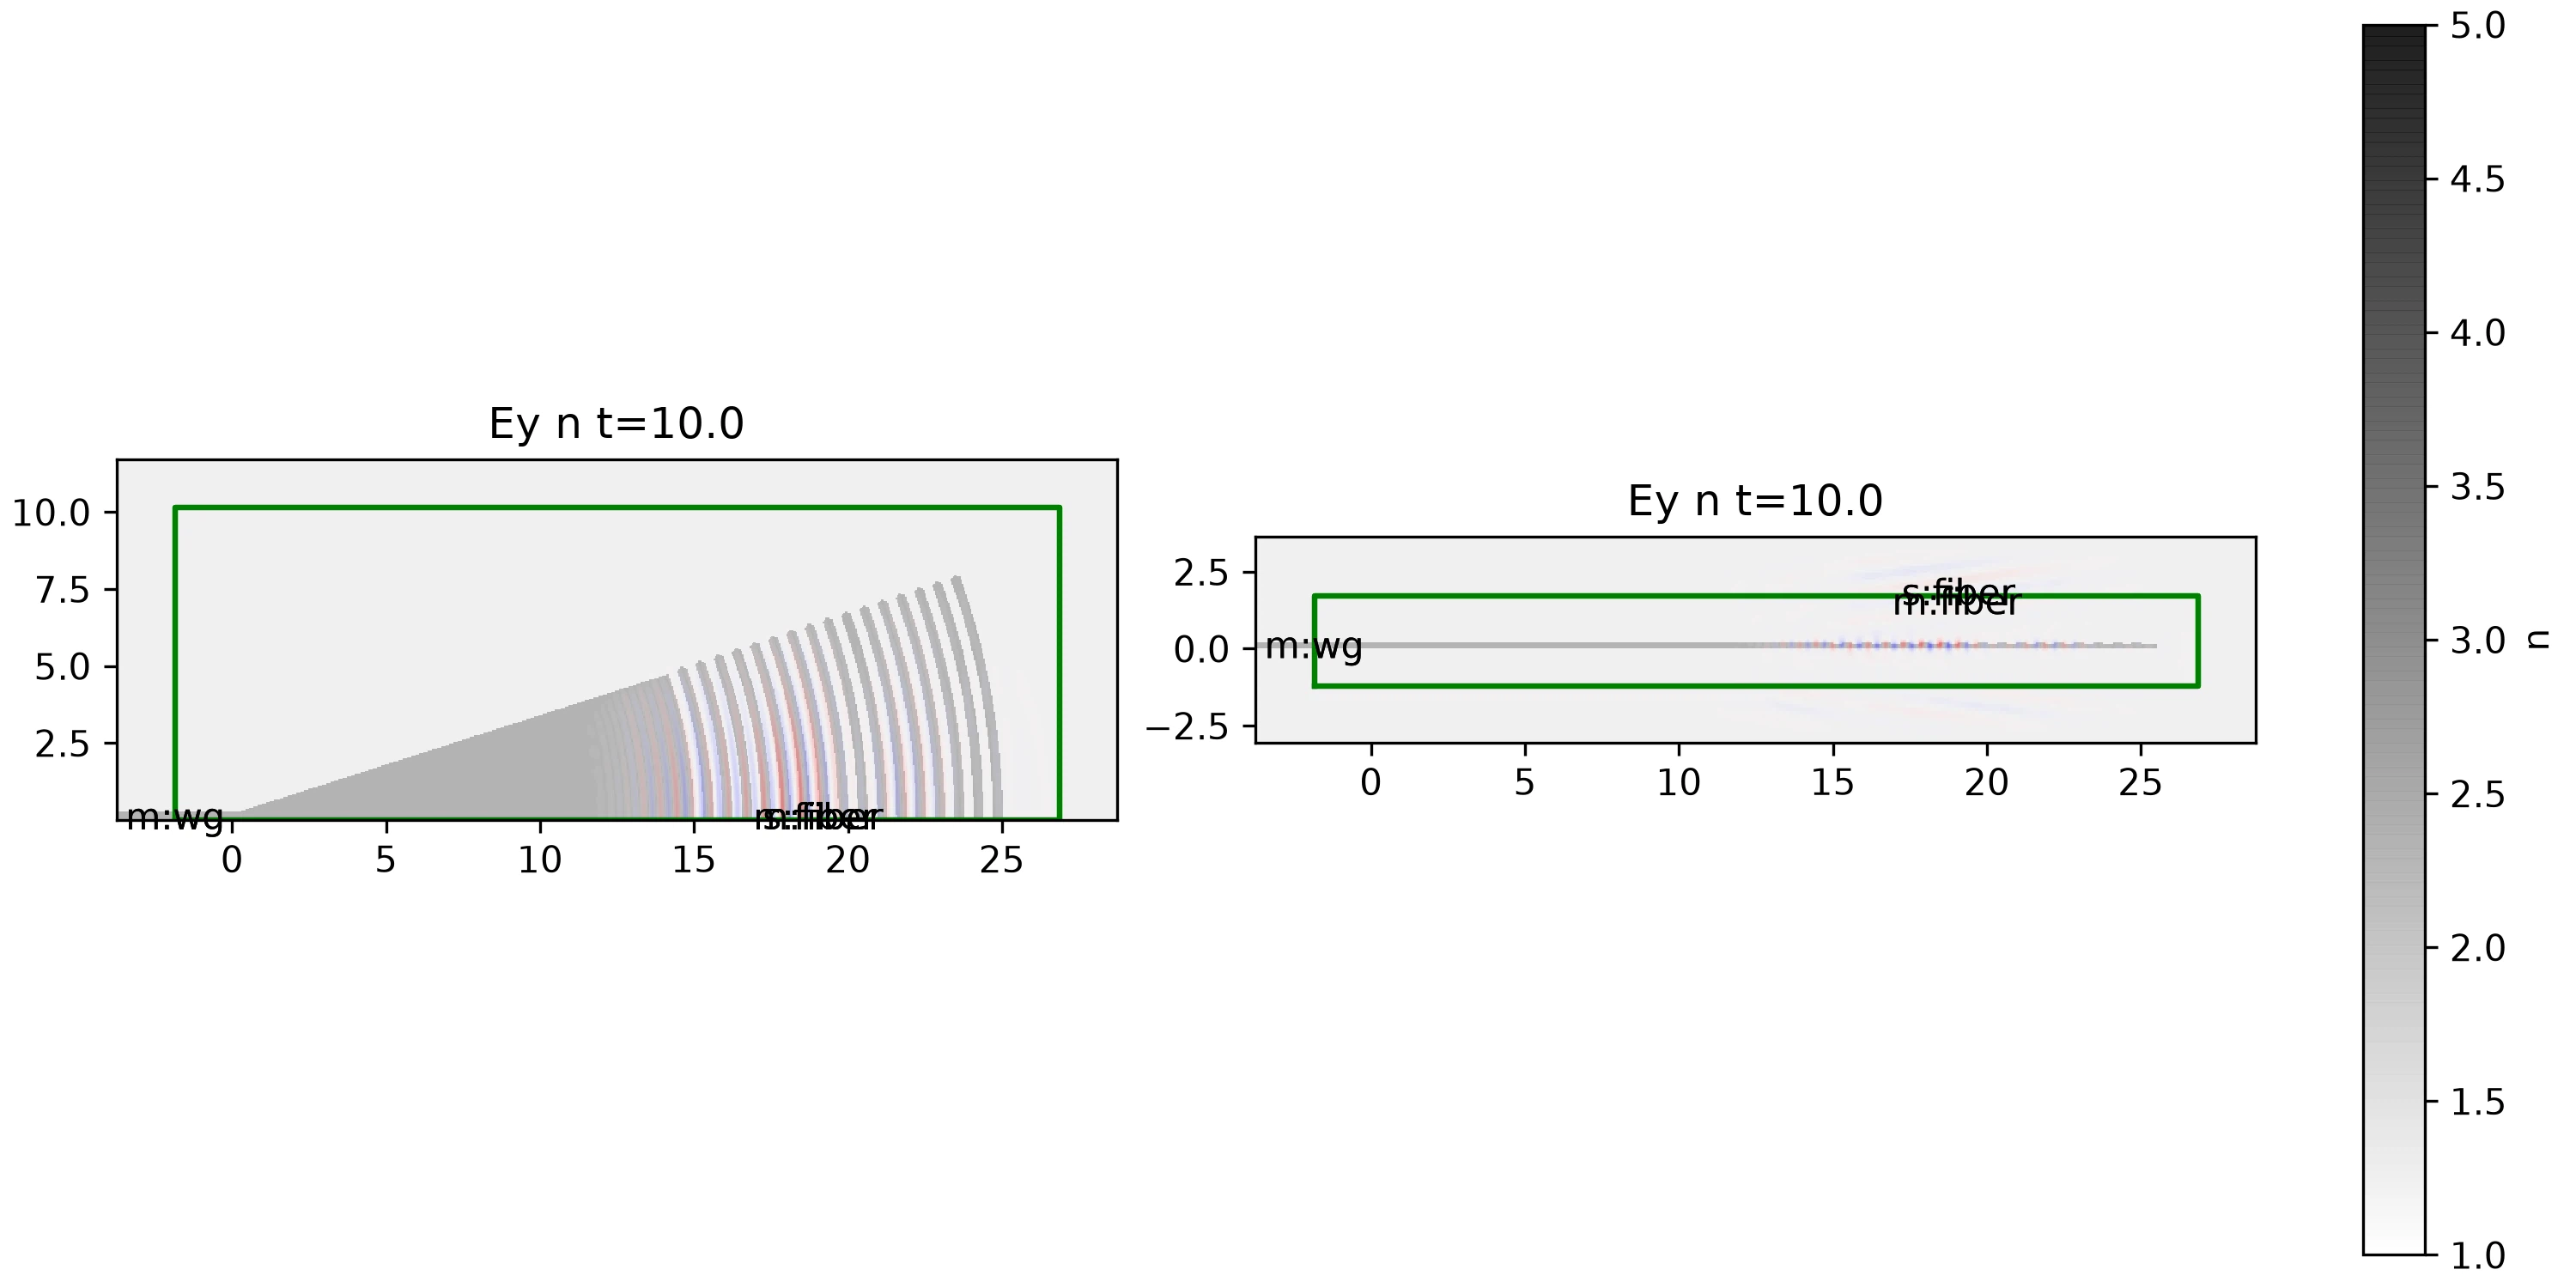

In [4]:
lumi.movie(path)
